# 04 Knowledge graph

**Goal:** turn the event timeline and the troubleshooting guide into one **knowledge graph**: dots (**nodes**) joined by labelled lines (**edges**).

It has two layers:
- **Knowledge layer** (from the guide): defects, causes, alarm codes, fixes, and the rules that link them. *"Alarm 2105 indicates dirty glass"*, *"dirty glass causes incomplete cut"*.
- **Event layer** (from the timeline): what actually happened. *"Alarm 2105 happened 3 h before job 340"*, *"job 340 has defect incomplete cut"*.

The two layers meet at the alarm codes, causes and defects. That's what lets the system walk from a bad job to a likely cause, with evidence.

This is the **event-centric knowledge graph** from your supervisor's direction, for now with logs and tables only (no photos or video).

We use **networkx** (included in Anaconda, so nothing to install). The graph is also saved as `kg_nodes.csv` and `kg_edges.csv`, which can be loaded into Neo4j later.

**The schema (ontology) is written down first** (step 0b): which kinds of nodes exist and which edges may join them. At the end the whole graph is checked against it.

## 0. Setup

In [1]:
from pathlib import Path
import pickle
import pandas as pd
import networkx as nx

DATA = Path("..") / "datasets"
OUT = Path("..") / "data" / "processed"

tl = pd.read_csv(OUT / "event_timeline.csv")
tl["time"] = pd.to_datetime(tl["time"], format="ISO8601")
G = nx.DiGraph()
print(len(tl), "timeline events")

1204 timeline events


## 0b. The schema (ontology): what kinds of nodes and edges are allowed
Knowledge-graph papers define the schema **before** filling in data (e.g. CTIThinker: 12 entity and 11 relation types; the KG-search paper: 5 entity types in Neo4j).
Here it is as two small tables. Every node and edge below must fit them, and step 5 checks that.

- **Concept nodes** (always true, from the guide): `Defect`, `Cause`, `Fix`, `AlarmCode`.
- **Event nodes** (happened once, have a time): `Job`, `AlarmEvent`, `Maintenance`, `Inspection`.
- Every node and edge also records its **`source`**: which file or guide section it came from. That is what lets an answer cite its evidence.

In [2]:
NODE_TYPES = {
    # concept nodes (knowledge layer, from the guide)
    "Defect": "a cut-quality problem (guide section 2)",
    "Cause": "a possible cause of a defect (guide section 2)",
    "Fix": "the remedy for a cause (guide sections 2 and 4)",
    "AlarmCode": "a machine message code (guide section 3)",
    # event nodes (event layer, from the timeline; each has a time)
    "Job": "one cutting job (job log)",
    "AlarmEvent": "one WARNING/ERROR message (alarm log)",
    "Maintenance": "one maintenance book entry",
    "Inspection": "one QC inspection of a job (inspection records)",
}

# edge type: (from node type, to node type, meaning)
SCHEMA = {
    "CAUSES":       ("Cause", "Defect", "the guide lists this cause for this defect (with rank, gas)"),
    "FIXED_BY":     ("Cause", "Fix", "the guide's remedy for this cause"),
    "INDICATES":    ("AlarmCode", "Cause", "the guide says this message points to this cause"),
    "NEXT":         ("Job", "Job", "the next job in time"),
    "INSPECTED_IN": ("Job", "Inspection", "the QC inspection of this job"),
    "FOUND":        ("Inspection", "Defect", "what the inspector found"),
    "HAS_DEFECT":   ("Job", "Defect", "shortcut for Job -INSPECTED_IN-> Inspection -FOUND-> Defect"),
    "INSTANCE_OF":  ("AlarmEvent", "AlarmCode", "this message is one occurrence of that code"),
    "DURING":       ("AlarmEvent", "Job", "the message happened while the job ran"),
    "LAST_ALARM":   ("Job", "AlarmEvent", "latest message of each code within 7 days before the job ended"),
    "RESETS":       ("Maintenance", "Cause", "this entry repaired that cause (keyword rule, step 4)"),
    "AFTER_REPAIR": ("Job", "Maintenance", "latest repair of each cause before the job started"),
}
pd.DataFrame([(t, a, b, m) for t, (a, b, m) in SCHEMA.items()], columns=["edge", "from", "to", "meaning"])

,edge,from,to,meaning
0,CAUSES,Cause,Defect,the guide lists this cause for this defect (wi...
1,FIXED_BY,Cause,Fix,the guide's remedy for this cause
2,INDICATES,AlarmCode,Cause,the guide says this message points to this cause
3,NEXT,Job,Job,the next job in time
4,INSPECTED_IN,Job,Inspection,the QC inspection of this job
5,FOUND,Inspection,Defect,what the inspector found
6,HAS_DEFECT,Job,Defect,shortcut for Job -INSPECTED_IN-> Inspection -F...
7,INSTANCE_OF,AlarmEvent,AlarmCode,this message is one occurrence of that code
8,DURING,AlarmEvent,Job,the message happened while the job ran
9,LAST_ALARM,Job,AlarmEvent,latest message of each code within 7 days befo...


## 1. Knowledge layer: written from the troubleshooting guide
These small tables are the guide (sections 2 to 4) typed out as data. Each row will become nodes and edges.

**Causes:** the guide lists the possible causes for each defect, most likely first (`rank`).
Some causes in the guide can't be checked with our data (for example focus position). They stay in the graph anyway, because the guide lists them, but the system will find no evidence for them.

**Checked against the guide PDF** (`datasets/documents/troubleshooting_guide.pdf`), row by row. Two modelling decisions to write in the report:
- Message **4001** (laser power reduced) points to `glass_dirty`, because the guide says it is "usually dirty optics". The guide's 4th incomplete-cut cause, "laser power reduced", is therefore folded into `glass_dirty`.
- "Height sensor not calibrated (message 3302)" is folded into `bevel_out_of_calibration`: the guide's fix for both is the same calibration.

In [3]:
# cause id -> description, the fix, a rule we can check in the data, and where in the guide it comes from
CAUSES = {
    "glass_dirty":              {"text": "Protective glass contaminated or damaged (beam power reduced)",
                                 "fix": "Clean or replace protective glass", "rule": "check every shift (8 h)", "source": "guide 2, 4"},
    "nozzle_worn":              {"text": "Nozzle worn or damaged (orifice no longer round)",
                                 "fix": "Replace nozzle", "rule": "replace every 40-60 operating hours", "source": "guide 2, 4"},
    "gas_supply_low":           {"text": "Cutting gas pressure too low or supply unstable",
                                 "fix": "Check tank, regulator and lines", "rule": "watch for messages 1201/1202", "source": "guide 2, 3"},
    "feed_too_high":            {"text": "Feed rate too high for the thickness",
                                 "fix": "Return to cutting-table feed rate", "rule": "max +10 % above cutting table; _FAST programs not released", "source": "guide 2, 5"},
    "bevel_out_of_calibration": {"text": "Bevel axis / height sensor out of calibration after a collision",
                                 "fix": "Calibrate height sensor and bevel axis", "rule": "calibrate after any collision", "source": "guide 2, 4"},
    "focus_wrong":              {"text": "Focus position wrong", "fix": "Run focus test", "rule": "not logged", "source": "guide 2"},
    "feed_too_low":             {"text": "Feed rate too low (overburning, mild steel)", "fix": "Increase feed rate", "rule": "compare with cutting table", "source": "guide 2"},
    "gas_pressure_too_high":    {"text": "Gas pressure too high (mild steel, O2)", "fix": "Check pressure against cutting table",
                                 "rule": "compare set pressure with cutting table", "source": "guide 2"},
    "material_surface":         {"text": "Material surface rusty or oily", "fix": "Use clean sheet", "rule": "not logged", "source": "guide 2"},
    "material_too_hot":         {"text": "Material too hot (dense nesting)", "fix": "Increase part spacing", "rule": "not logged", "source": "guide 2"},
    "wrong_bevel_program":      {"text": "Wrong bevel program or tool", "fix": "Check bevel program; measure first part with protractor",
                                 "rule": "not logged", "source": "guide 2"},
}

# (defect, cause, rank, only for gas)  - guide section 2, most likely first
CAUSES_DEFECT = [
    ("dross", "gas_supply_low", 1, "N2"), ("dross", "nozzle_worn", 2, "N2"), ("dross", "focus_wrong", 3, "N2"), ("dross", "feed_too_high", 4, "N2"),
    ("dross", "feed_too_low", 1, "O2"), ("dross", "gas_pressure_too_high", 2, "O2"), ("dross", "material_surface", 3, "O2"),
    ("rough_cut", "feed_too_high", 1, None), ("rough_cut", "nozzle_worn", 2, None), ("rough_cut", "glass_dirty", 3, None),
    ("incomplete_cut", "glass_dirty", 1, None), ("incomplete_cut", "feed_too_high", 2, None), ("incomplete_cut", "focus_wrong", 3, None),
    ("bevel_deviation", "bevel_out_of_calibration", 1, None), ("bevel_deviation", "wrong_bevel_program", 2, None),
    ("burnt_edge", "glass_dirty", 1, None), ("burnt_edge", "feed_too_low", 2, None), ("burnt_edge", "material_too_hot", 3, None),
]

# alarm code -> the cause it points to (guide section 3)
INDICATES = {"2105": "glass_dirty", "4001": "glass_dirty", "1201": "gas_supply_low", "1202": "gas_supply_low",
             "3301": "bevel_out_of_calibration", "3302": "bevel_out_of_calibration"}
# message texts as written in guide section 3 (6002 sheet tip-up points to no cause in the guide)
ALARM_TEXT = {"1201": "Cutting gas pressure below setpoint", "1202": "Cutting gas pressure fluctuation",
              "2105": "Protective glass contamination - check and clean", "3301": "Collision detected - cutting head",
              "3302": "Capacitive height sensor - calibration required", "4001": "Laser power reduced - beam path monitoring",
              "6002": "Sheet tip-up detected - check part"}

In [4]:
for cid, c in CAUSES.items():
    G.add_node(f"cause:{cid}", kind="Cause", name=cid, **c)
    G.add_node(f"fix:{cid}", kind="Fix", name=c["fix"], source=c["source"])
    G.add_edge(f"cause:{cid}", f"fix:{cid}", type="FIXED_BY", source=c["source"])

for defect, cid, rank, gas in CAUSES_DEFECT:
    G.add_node(f"defect:{defect}", kind="Defect", name=defect, source="guide 2")
    G.add_edge(f"cause:{cid}", f"defect:{defect}", type="CAUSES", rank=rank, gas=gas or "any", source="guide 2")

for code_, text in ALARM_TEXT.items():
    G.add_node(f"code:{code_}", kind="AlarmCode", name=code_, text=text, source="guide 3")
for code_, cid in INDICATES.items():
    G.add_edge(f"code:{code_}", f"cause:{cid}", type="INDICATES", source="guide 3")

print("knowledge layer:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

knowledge layer: 34 nodes, 35 edges


## 2. Event layer: jobs
Each job becomes a node that carries its settings. We re-read the job log for the full settings (same cleaning as notebooks 01 and 03), and add the two columns from the EDA that the guide's rules need:
`feed_vs_table` (feed ÷ cutting-table feed) and `is_fast`.

Jobs are linked in time order with `NEXT`.

Each **inspection** is its own event node (it has a time and an inspector), so later a photo of the cut edge can hang off it. The guide (section 6) says the photo is named with the job ID. The chain is `Job -INSPECTED_IN-> Inspection -FOUND-> Defect`. We also keep the one-step shortcut `Job -HAS_DEFECT-> Defect`, which notebook 05 uses.

In [5]:
jobs = pd.read_csv(DATA / "machine" / "job_log.csv", sep=";", decimal=",").drop_duplicates()
jobs["StartTime"] = pd.to_datetime(jobs["StartTime"], format="%d.%m.%Y %H:%M:%S")
jobs["EndTime"] = pd.to_datetime(jobs["EndTime"], format="%d.%m.%Y %H:%M:%S")
jobs = jobs.sort_values("StartTime").reset_index(drop=True)
jobs["NozzleOperatingHours"] = jobs["NozzleOperatingHours"].ffill()     # same decision as notebook 03

table = pd.read_csv(DATA / "documents" / "cutting_table.csv").rename(columns={
    "material": "Material", "gas": "CuttingGas", "thickness_mm": "Thickness_mm", "feed_rate_mm_min": "table_feed"})
jobs = jobs.merge(table[["Material", "CuttingGas", "Thickness_mm", "table_feed"]], on=["Material", "CuttingGas", "Thickness_mm"], how="left")
jobs["feed_vs_table"] = (jobs["FeedRate_mm_min"] / jobs["table_feed"]).round(2)
jobs["is_fast"] = jobs["ProgramName"].str.contains("_FAST")

insp = tl[tl["event_type"] == "inspection"][["job_id", "detail"]].copy()
insp["defect"] = insp["detail"].str.split(" | ", regex=False).str[1]
jobs = jobs.merge(insp[["job_id", "defect"]], left_on="JobID", right_on="job_id", how="left").drop(columns="job_id")

for _, j in jobs.iterrows():
    G.add_node(f"job:{j['JobID']}", kind="Job", name=j["JobID"], start=j["StartTime"], end=j["EndTime"],
               program=j["ProgramName"], material=j["Material"], thickness=float(j["Thickness_mm"]), gas=j["CuttingGas"],
               feed=float(j["FeedRate_mm_min"]), feed_vs_table=float(j["feed_vs_table"]), is_fast=bool(j["is_fast"]),
               bevel_angle=float(j["BevelAngle_deg"]), nozzle_hours=float(j["NozzleOperatingHours"]),
               gas_pressure_set=float(j["GasPressureSet_bar"]), shift="late" if j["StartTime"].hour >= 14 else "early",
               source="job_log")
    if pd.notna(j["defect"]) and j["defect"] != "unknown":
        G.add_node(f"defect:{j['defect']}", kind="Defect", name=j["defect"], source="guide 2")
        G.add_edge(f"job:{j['JobID']}", f"defect:{j['defect']}", type="HAS_DEFECT", source="inspection_records")

# inspections as event nodes: Job -INSPECTED_IN-> Inspection -FOUND-> Defect
for i, row in tl[tl["event_type"] == "inspection"].reset_index(drop=True).iterrows():
    result, defect = row["detail"].split(" | ")[:2]
    node = f"insp:{i}"
    G.add_node(node, kind="Inspection", name=row["job_id"], time=row["time"], result=result, defect=defect, source=row["source"])
    if f"job:{row['job_id']}" in G:
        G.add_edge(f"job:{row['job_id']}", node, type="INSPECTED_IN", source=row["source"])
    if defect != "unknown":
        G.add_node(f"defect:{defect}", kind="Defect", name=defect, source="guide 2")
        G.add_edge(node, f"defect:{defect}", type="FOUND", source=row["source"])

ids = jobs["JobID"].tolist()
for a, b in zip(ids[:-1], ids[1:]):
    G.add_edge(f"job:{a}", f"job:{b}", type="NEXT")
print(len(jobs), "job nodes")

527 job nodes


## 3. Event layer: alarms
Each WARNING/ERROR alarm becomes a node, linked to its code (`INSTANCE_OF`) and to the job it happened during (`DURING`, from notebook 01).

Then the important part. For each job and each alarm code, we link the job to the **most recent** alarm of that code before the job ended (`LAST_ALARM`), within 7 days.
The edge stores how many hours before the job it was, and how many of that code happened in the 24 h before.
This lets the system ask "what alarms came before this job?" with one step through the graph.

In [6]:
alarms = tl[tl["event_type"] == "alarm"].reset_index(drop=True)
alarms["code"] = alarms["detail"].str.split(" ").str[0]
alarms["node"] = "alarm:" + alarms.index.astype(str)

for _, a in alarms.iterrows():
    G.add_node(a["node"], kind="AlarmEvent", name=a["code"], time=a["time"], text=a["detail"], source=a["source"])
    G.add_node(f"code:{a['code']}", kind="AlarmCode", name=a["code"])
    G.add_edge(a["node"], f"code:{a['code']}", type="INSTANCE_OF")
    if pd.notna(a["job_id"]):
        G.add_edge(a["node"], f"job:{a['job_id']}", type="DURING")

n_last = 0
for _, j in jobs.iterrows():
    before = alarms[(alarms["time"] <= j["EndTime"]) & (alarms["time"] >= j["StartTime"] - pd.Timedelta(days=7))]
    for code_, grp in before.groupby("code"):
        last = grp.iloc[-1]
        n24 = (grp["time"] >= j["StartTime"] - pd.Timedelta(hours=24)).sum()
        hours = round((j["StartTime"] - last["time"]).total_seconds() / 3600, 1)    # negative = during the job
        G.add_edge(f"job:{j['JobID']}", last["node"], type="LAST_ALARM", code=code_, hours_before=hours, count_24h=int(n24))
        n_last += 1
print(len(alarms), "alarm nodes,", n_last, "LAST_ALARM edges")

217 alarm nodes, 1665 LAST_ALARM edges


## 4. Event layer: maintenance
Each maintenance entry becomes a node. Entries that **repair** something get a `RESETS` edge to the cause they fix.
The operators wrote free text, so we decide this from keywords (a decision to write in the report):

| keywords | resets |
|---|---|
| glass + clean / wiped / replaced (not "will clean tomorrow") | `glass_dirty` |
| nozzle + changed / replaced / new / fitted (not "no change") | `nozzle_worn` |
| regulator | `gas_supply_low` |
| recalibrat | `bevel_out_of_calibration` |

Then each job is linked to the **last repair before it** for each cause (`AFTER_REPAIR`), with the hours since. That's how "the glass hadn't been cleaned for 30 hours" becomes one edge.

Some entries say *(time estimated)*: the operator wrote the time afterwards. Those nodes get `time_estimated=True`, so an answer can say how sure the time is.

In [7]:
maint = tl[tl["event_type"].str.startswith("maintenance")].reset_index(drop=True)
maint["node"] = "maint:" + maint.index.astype(str)

def resets(text):
    t = text.lower()
    if "glass" in t and any(w in t for w in ["clean", "wiped", "replaced"]) and "tomorrow" not in t:
        return "glass_dirty"
    if "nozzle" in t and any(w in t for w in ["changed", "replaced", "new nozzle", "fitted"]) and "no change" not in t:
        return "nozzle_worn"
    if "regulator" in t:
        return "gas_supply_low"
    if "recalibrat" in t:
        return "bevel_out_of_calibration"
    return None

maint["resets"] = maint["detail"].apply(resets)
for _, m in maint.iterrows():
    G.add_node(m["node"], kind="Maintenance", name=m["event_type"], time=m["time"], text=m["detail"],
               time_estimated="time estimated" in m["detail"], source=m["source"])
    if pd.notna(m["resets"]):
        G.add_edge(m["node"], f"cause:{m['resets']}", type="RESETS")

repairs = maint.dropna(subset=["resets"])
n_rep = 0
for _, j in jobs.iterrows():
    for cid, grp in repairs[repairs["time"] <= j["StartTime"]].groupby("resets"):
        last = grp.iloc[-1]
        hours = round((j["StartTime"] - last["time"]).total_seconds() / 3600, 1)
        G.add_edge(f"job:{j['JobID']}", last["node"], type="AFTER_REPAIR", cause=cid, hours_since=hours)
        n_rep += 1
print(len(maint), "maintenance nodes,", len(repairs), "are repairs,", n_rep, "AFTER_REPAIR edges")
maint[["time", "detail", "resets"]]

44 maintenance nodes, 35 are repairs, 1306 AFTER_REPAIR edges


,time,detail,resets
0,2026-09-01 06:04:00,"glass ok, wiped",glass_dirty
1,2026-09-01 06:10:00,"new nozzle fitted, start of month",nozzle_worn
2,2026-09-02 06:18:00,"glass ok, wiped",glass_dirty
3,2026-09-03 14:05:00,"protective glass checked, cleaned",glass_dirty
4,2026-09-05 14:19:00,"glass ok, wiped",glass_dirty
5,2026-09-07 06:00:00,"protective glass checked, cleaned (time estima...",glass_dirty
6,2026-09-07 14:00:00,"glass ok, wiped (time estimated)",glass_dirty
7,2026-09-08 06:00:00,"nozzle changed, routine (time estimated)",nozzle_worn
8,2026-09-10 06:06:00,"checked prot. glass - slight spatter, cleaned",glass_dirty
9,2026-09-11 06:11:00,"checked prot. glass - slight spatter, cleaned",glass_dirty


## 5. Look at the graph
Count the nodes and edges of each kind, then look at the neighbourhood of one bad job.

In [8]:
print(pd.Series([d["kind"] for _, d in G.nodes(data=True)]).value_counts().to_string())
print()
print(pd.Series([d["type"] for _, _, d in G.edges(data=True)]).value_counts().to_string())

Job            527
Inspection     416
AlarmEvent     217
Maintenance     44
Cause           11
Fix             11
AlarmCode        7
Defect           6

LAST_ALARM      1665
AFTER_REPAIR    1306
NEXT             526
INSPECTED_IN     416
HAS_DEFECT       402
FOUND            402
INSTANCE_OF      217
DURING           217
RESETS            35
CAUSES            18
FIXED_BY          11
INDICATES          6


### Check the graph against the schema
Every node must be one of the 8 node types, and every edge must join the two node types its row in `SCHEMA` says.
A typo such as `HAS_DEFFECT`, or an edge between the wrong kinds of node, stops the notebook here instead of slipping through.

In [9]:
bad_nodes = [n for n, d in G.nodes(data=True) if d.get("kind") not in NODE_TYPES]
bad_edges = [(u, v, d.get("type")) for u, v, d in G.edges(data=True)
             if SCHEMA.get(d.get("type"), (None, None))[:2] != (G.nodes[u].get("kind"), G.nodes[v].get("kind"))]
no_source = [n for n, d in G.nodes(data=True) if not d.get("source")]
assert not bad_nodes, f"nodes with an unknown kind: {bad_nodes[:5]}"
assert not bad_edges, f"edges that break the schema: {bad_edges[:5]}"
assert not no_source, f"nodes without a source: {no_source[:5]}"
print(f"schema check passed: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, all with a known type and a source")

schema check passed: 1239 nodes, 5221 edges, all with a known type and a source


In [10]:
JOB = "job:JOB-00391"      # change to any job id
print(JOB, {k: v for k, v in G.nodes[JOB].items() if k in ["program", "gas", "nozzle_hours", "feed_vs_table", "is_fast"]})
for _, target, e in G.out_edges(JOB, data=True):
    if e["type"] != "NEXT":
        print(f"  -{e['type']}-> {target}: {G.nodes[target].get('text', G.nodes[target]['name'])}",
              {k: v for k, v in e.items() if k != "type"})

job:JOB-00391 {'program': 'S235JR_12mm_BEV', 'gas': 'O2', 'feed_vs_table': 1.01, 'is_fast': False, 'nozzle_hours': 14.2}
  -HAS_DEFECT-> defect:incomplete_cut: incomplete_cut {'source': 'inspection_records'}
  -INSPECTED_IN-> insp:310: JOB-00391 {'source': 'inspection_records'}
  -LAST_ALARM-> alarm:97: 1201 WARNING | Cutting gas pressure below setpoint (N2, set 14.2 bar, actual 9.4 bar) {'code': '1201', 'hours_before': 159.8, 'count_24h': 0}
  -LAST_ALARM-> alarm:145: 2105 WARNING | Protective glass contamination - check and clean {'code': '2105', 'hours_before': 10.5, 'count_24h': 10}
  -LAST_ALARM-> alarm:146: 4001 WARNING | Laser power reduced - beam path monitoring {'code': '4001', 'hours_before': -0.1, 'count_24h': 4}
  -LAST_ALARM-> alarm:108: 6002 WARNING | Sheet tip-up detected - check part {'code': '6002', 'hours_before': 92.9, 'count_24h': 0}
  -AFTER_REPAIR-> maint:27: facilities replaced N2 pressure regulator at tank, pressure ok again {'cause': 'gas_supply_low', 'hours_si

### Figure: one bad job and what it connects to
Blue = job, red = defect, orange = alarms, green = maintenance, purple = causes from the guide.
Follow the arrows: the job's alarms point to causes, and the same causes point to the job's defect. That shared cause is the explanation.

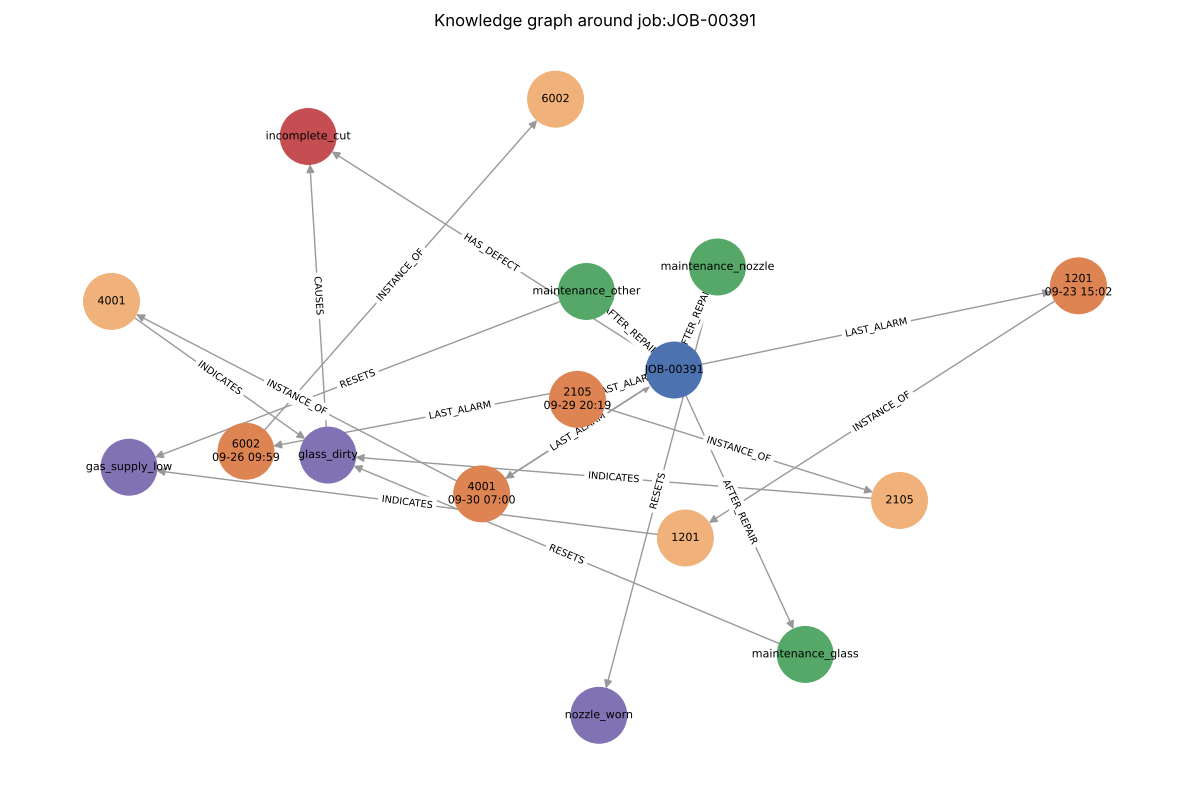

In [11]:
import matplotlib.pyplot as plt

def neighbourhood(job):
    nodes = {job}
    for _, t, e in G.out_edges(job, data=True):
        if e["type"] in ("HAS_DEFECT", "LAST_ALARM", "AFTER_REPAIR"):
            nodes.add(t)
            for _, t2, e2 in G.out_edges(t, data=True):
                if e2["type"] in ("INSTANCE_OF", "RESETS"):
                    nodes.add(t2)
    for n in list(nodes):
        if n.startswith("code:"):
            nodes.update(t for _, t, e in G.out_edges(n, data=True) if e["type"] == "INDICATES")
    defect = [t for _, t, e in G.out_edges(job, data=True) if e["type"] == "HAS_DEFECT"]
    for d in defect:
        nodes.update(s for s, _, e in G.in_edges(d, data=True) if e["type"] == "CAUSES" and s in nodes)
    return G.subgraph(nodes)

H = neighbourhood(JOB)
colour = {"Job": "#4C72B0", "Defect": "#C44E52", "AlarmEvent": "#DD8452", "AlarmCode": "#F0B27A",
          "Maintenance": "#55A868", "Cause": "#8172B3"}
labels = {n: (d.get("name") if d["kind"] != "AlarmEvent" else d["name"] + "\n" + str(d["time"])[5:16]) for n, d in H.nodes(data=True)}
pos = nx.spring_layout(H, seed=3, k=1.2)
plt.figure(figsize=(12, 8))
nx.draw_networkx(H, pos, labels=labels, node_color=[colour.get(d["kind"], "grey") for _, d in H.nodes(data=True)],
                 node_size=1600, font_size=8, edge_color="#999999", arrowsize=12)
nx.draw_networkx_edge_labels(H, pos, edge_labels={(u, v): d["type"] for u, v, d in H.edges(data=True)}, font_size=7)
plt.title(f"Knowledge graph around {JOB}")
plt.axis("off")
plt.tight_layout()
(OUT / "figures").mkdir(exist_ok=True)
plt.savefig(OUT / "figures" / "fig5_graph_one_job.png", dpi=200)
plt.show()

## 6. Save
- `knowledge_graph.pkl`: the whole graph, loaded by notebook 05.
- `kg_nodes.csv` and `kg_edges.csv`: the same graph as two tables, ready for Neo4j (`LOAD CSV`) or for a figure in the report. Edges use `from_id` / `to_id` for their two ends; `source` on a node or edge always means where the fact came from.

In [12]:
with open(OUT / "knowledge_graph.pkl", "wb") as f:
    pickle.dump(G, f)

pd.DataFrame([{"id": n, **{k: v for k, v in d.items()}} for n, d in G.nodes(data=True)]).to_csv(OUT / "kg_nodes.csv", index=False)
# from_id / to_id, because "source" is already the provenance property (which file or guide section)
edges = pd.DataFrame([{"from_id": u, "to_id": v, **d} for u, v, d in G.edges(data=True)])
assert edges["from_id"].isin(G.nodes).all() and edges["to_id"].isin(G.nodes).all(), "edge ends missing from the node list"
edges.to_csv(OUT / "kg_edges.csv", index=False)
print("saved graph:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

saved graph: 1239 nodes, 5221 edges


## What this notebook showed
- The **knowledge layer** is the troubleshooting guide as data: causes → defects, alarm codes → causes, causes → fixes.
- The **event layer** is the timeline as data: jobs, alarms, maintenance, inspections, and how they sit in time.
- The two layers meet at alarm codes, causes and defects. A walk like *job → alarm 2105 → glass_dirty → incomplete_cut* is an explanation with evidence.
- The **schema** (step 0b) is the ontology: 8 node types and 12 edge types. Every node keeps its **source** (file or guide section), and the graph is checked against the schema before saving. Paste the schema table into the report.
- Decisions to write down: the 7-day / 24-hour windows for alarms, the keyword rules for which maintenance counts as a repair, and the two guide rows folded into other causes (4001, 3302).

**Next (notebook 05):** for each bad job, collect this walk as evidence and give it to the LLM.